## INFORME EJECUTIVO: SOLUCIÓN INTEGRAL DE VISUAL ANALYTICS

Proyecto: Optimización Estratégica del Catálogo Audiovisual y Gobernanza Analítica

Organización: StreamView Analytics

Audiencias Principales: Directorio, Gerencia General, Gerencia de Adquisición y Gestión de Contenidos, Gerencia de Marketing, Equipo de Data & Analytics



### 1. Descripción del Problema de Negocio
StreamView Analytics es una plataforma internacional de streaming con operaciones consolidadas y en expansión en Latinoamérica. A lo largo de los últimos años, la compañía experimentó un crecimiento acelerado en el volumen de títulos disponibles (largometrajes y series de televisión); sin embargo, dicho volumen no se tradujo en conocimiento estratégico accionable. La organización dispone de datos suficientes, pero la ausencia de soluciones centralizadas de Visual Analytics fragmentó la interpretación de la información y limitó la capacidad de las distintas áreas operacionales para identificar tendencias y ventajas competitivas.

El diagnóstico corporativo reveló siete problemas críticos de información:

Falta de visión consolidada del catálogo: Las áreas operan de forma aislada, utilizando reportes independientes con criterios desalineados.

Opacidad en la demanda de géneros: Dificultad para identificar con rapidez qué géneros concentran la mayor popularidad y engagement en la plataforma.

Decisiones de adquisición asimétricas: Las compras y renovaciones de derechos de transmisión se realizan con información parcial o intuición, sin un soporte empírico robusto.

Carencia de benchmarking geográfico: Inexistencia de un mecanismo simple para comparar el volumen, la calidad y el rendimiento de los países productores globales y regionales.

Falta de información consolidada en Marketing: Incapacidad de identificar oportunamente qué títulos priorizar en campañas promocionales pagadas y qué segmentos del catálogo poseen mayor potencial de posicionamiento.

Desconocimiento del perfil de contenido exitoso: La Gerencia de Adquisiciones requiere comprender con exactitud qué atributos (clasificación etaria, duración, origen, combinaciones temáticas) poseen los títulos mejor evaluados y más populares.

Deficiencias severas en dashboards existentes: Los cuadros de mando heredados presentan sobrecarga cognitiva, exceso de métricas irrelevantes, elección gráfica errónea y nula interactividad analítica.

Antes de construir cualquier solución de visualización, los estudiantes deberán revisar la calidad de la información considerando
aspectos como:
* valores nulos;
* registros duplicados;
* formatos inconsistentes;
* variables categóricas;
* fechas;
* valores atípicos;

# librerias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [ ]:
# Enlaces "Raw" directos desde tu repositorio de GitHub
url_movies = "https://raw.githubusercontent.com/YorkiOprogramador/VisualizacionDeDatos_Encargo1/main/data/netflix_movies_detailed_up_to_2025.csv"
url_shows = "https://raw.githubusercontent.com/YorkiOprogramador/VisualizacionDeDatos_Encargo1/main/data/netflix_tv_shows_detailed_up_to_2025.csv"

# Leer los archivos CSV
df_movies = pd.read_csv(url_movies)
df_shows = pd.read_csv(url_shows)



In [ ]:
df_movies['genres'].unique()

array(['Comedy, Adventure, Fantasy, Animation, Family',
       'Action, Science Fiction, Adventure', 'Adventure, Fantasy', ...,
       'Action, Thriller, Romance, Fantasy, Drama', 'Music, Animation',
       'Drama, Thriller, Mystery, Horror'], dtype=object)

# Set de datos de peliculas

In [ ]:
print("--- Dataset de Películas (Movies) ---")
display(df_movies.head(3))



--- Dataset de Películas (Movies) ---


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,NaN,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000,752600867
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,NaN,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000,839030630
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,NaN,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000,954305868


In [ ]:
df_movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      15868 non-null  object 
 4   cast          15796 non-null  object 
 5   country       15534 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      0 non-null      float64
 10  genres        15893 non-null  object 
 11  language      16000 non-null  object 
 12  description   15868 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
 16  budget        16000 non-null  int64  
 17  revenue       16000 non-null  int64  
dtypes: float64(4), int64(5), o

Presentan valores nulos:
* Director
* Cast
* Country
* Duration
* genres
* description



In [ ]:
df_movies_numerico = df_movies.drop(columns="show_id").select_dtypes(include=['int', 'float']).describe()
display(df_movies_numerico)

,release_year,rating,duration,popularity,vote_count,vote_average,budget,revenue
count,16000.000000,16000.000000,0.0,16000.000000,16000.000000,16000.000000,1.600000e+04,1.600000e+04
mean,2017.500000,5.956368,NaN,20.384728,718.656125,5.956368,8.766792e+06,2.446308e+07
std,4.609916,1.754741,NaN,68.610033,2080.198316,1.754741,2.912450e+07,1.116977e+08
min,2010.000000,0.000000,NaN,3.860000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,2013.750000,5.600000,NaN,7.840750,53.000000,5.600000,0.000000e+00,0.000000e+00
50%,2017.500000,6.300000,NaN,10.913500,138.000000,6.300000,0.000000e+00,0.000000e+00
75%,2021.250000,6.923000,NaN,17.336500,422.000000,6.923000,2.200000e+06,1.654473e+06
max,2025.000000,10.000000,NaN,3876.006000,37119.000000,10.000000,4.600000e+08,2.799439e+09


In [ ]:
df_movies['duration'].unique()

array([nan])

La variable duration está completamente vacía

In [ ]:
df_movies_categorico = df_movies.drop(columns="show_id").select_dtypes(include=['object']).describe()
display(df_movies_categorico)

,type,title,director,cast,country,date_added,genres,language,description
count,16000,16000,15868,15796,15534,16000,15893,16000,15868
unique,1,15485,9508,15639,1463,4423,2768,74,15854
top,Movie,Eden,Tyler Perry,"Wasabi Mizuta, Megumi Oohara, Yumi Kakazu, Sub...",United States of America,2025-03-07,Drama,en,A narrative short film.
freq,16000,6,20,10,5421,103,1336,9534,9


In [ ]:
# Contar cuántos registros duplicados existen basados en 'show_id'
duplicados = df_movies.duplicated(subset=['show_id']).sum()

# Imprimir el resultado
print(f"Total de registros duplicados por 'show_id': {duplicados}")

# Opcional: Si quieres ver cuáles son esos registros duplicados (en caso de que existan)
if duplicados > 0:
    filas_duplicadas = df_movies[df_movies.duplicated(subset=['show_id'], keep=False)]
    print("\nMostrando las filas duplicadas:")
    display(filas_duplicadas)

Total de registros duplicados por 'show_id': 0


* No hay duplicados por show_id, pero, en titulos de los 16_000 registros solo 15485 son valores unicos ¿A que se debe? Analizar

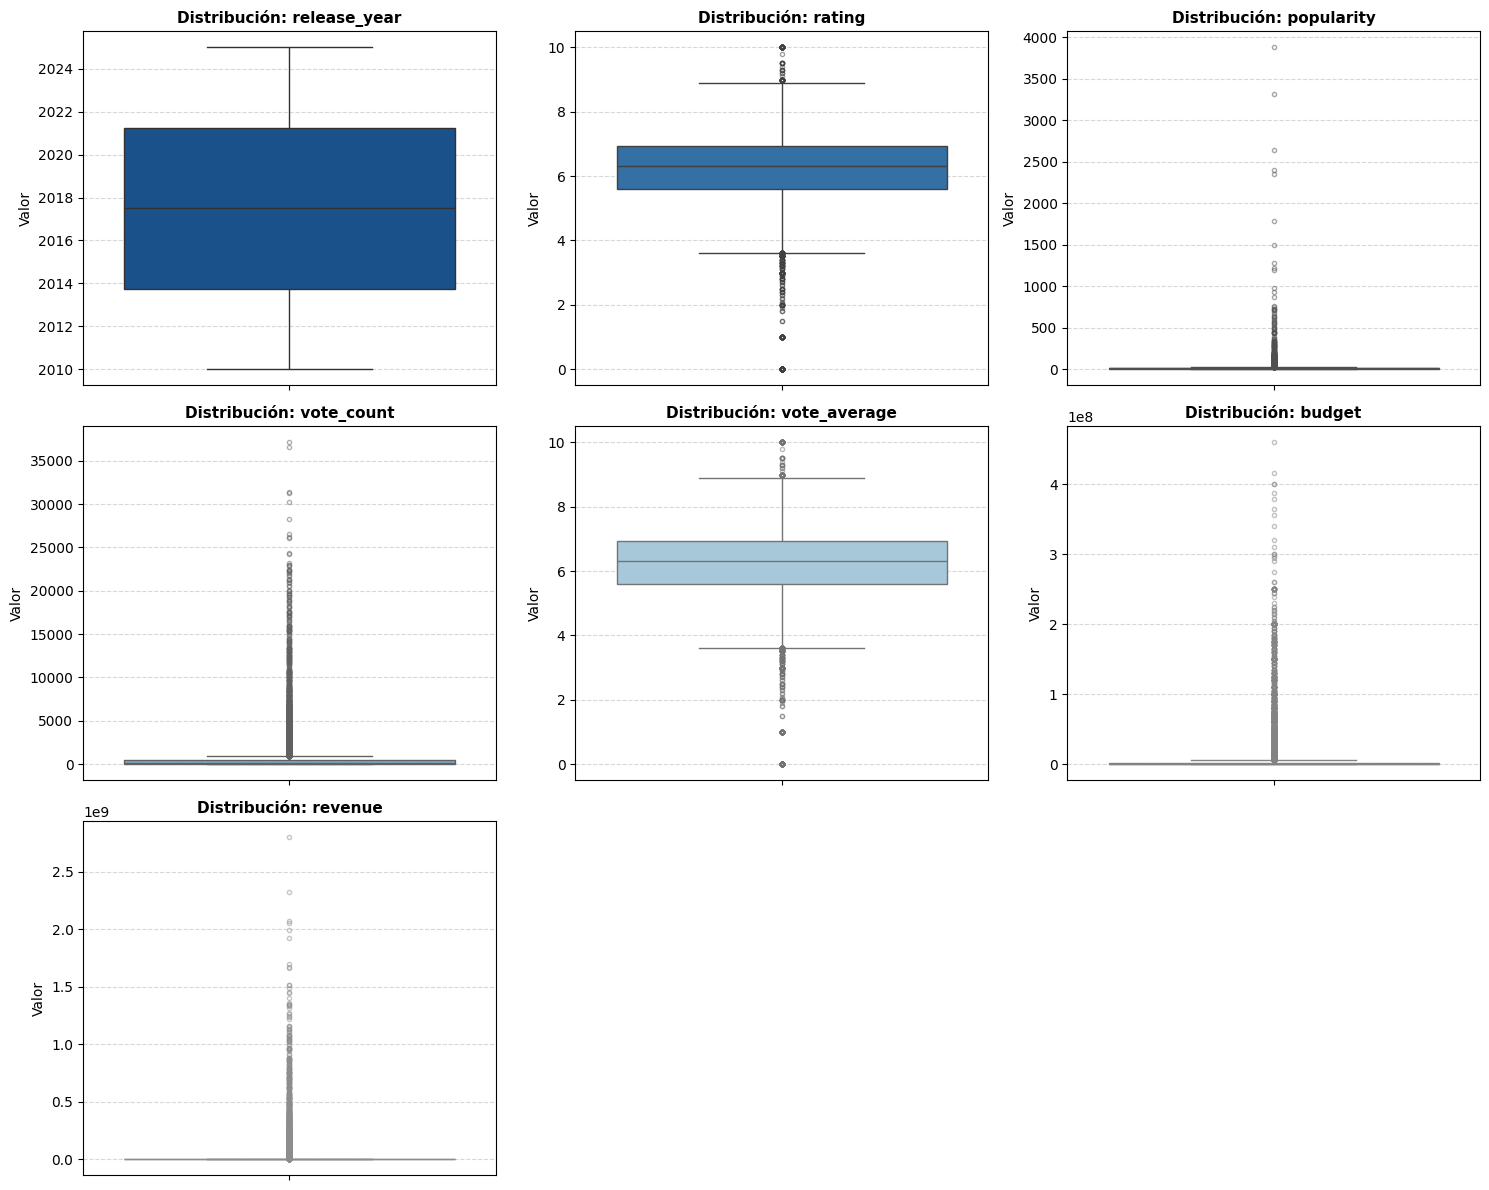

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

"""
    Genera una cuadrícula de diagramas de caja (boxplots) para todas las
    variables numéricas válidas del catálogo de películas.

    Propósito Metodológico y Visual Analytics:
    -----------------------------------------
    - Análisis de la Distribución: Permite analizar la simetría de los datos,
      la dispersión intercuartílica (IQR) y la mediana de variables continuas y
      discretas.
    - Detección de Valores Atípicos: Identifica valores extremos (outliers)
      mediante el criterio de 1.5 * IQR[cite: 5, 8].
    - Independencia de Escalas: Genera subgráficos individuales (subplots) para
      prevenir la distorsión visual provocada por magnitudes incompatibles (por
      ejemplo, 'vote_average' en rango [0, 10] frente a 'budget' y 'revenue' en
      millones de USD)[cite: 1, 6].

    Tratamiento y Reglas de Negocio de Datos:
    -----------------------------------------
    1. Aislamiento de Identificadores: Se excluye 'show_id' por ser una variable
       categórica nominal (llave primaria) no apta para operaciones estadísticas[cite: 1, 6].
    2. Depuración de Nulos: Se eliminan columnas 100% nulas y se aplica dropna()
       a cada serie para evitar la excepción ValueError (descalce de posiciones)
       en la renderización de Matplotlib.
    3. Optimización Espacial: Calcula filas y columnas dinámicamente según la
       cantidad de variables y oculta ejes sobrantes para preservar la jerarquía
       y el balance visual[cite: 7, 9].

    Parámetros:
    -----------
    df_movies : pd.DataFrame
        DataFrame que contiene el catálogo de películas con columnas numéricas
        (int64, float64).

    Retorno:
    --------
    None : Despliega la figura directamente en pantalla mediante plt.show().
    """

# 1. Obtener columnas numéricas sobre datos crudos (excluyendo show_id)
#    y descartar columnas que sean 100% nulas
df_num = df_movies.drop(columns=["show_id"], errors="ignore").select_dtypes(include=['int', 'float'])
df_num = df_num.dropna(how='all', axis=1)

# 2. Filtrar únicamente columnas con datos válidos
cols = [c for c in df_num.columns if df_num[c].dropna().shape[0] > 0]
n_cols = len(cols)

# 3. Configurar cuadrícula
grid_cols = 3
grid_rows = math.ceil(n_cols / grid_cols)

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, 4 * grid_rows))
axes = axes.flatten() if n_cols > 1 else [axes]
palette = sns.color_palette("Blues_r", n_cols)

# 4. Graficar aplicando dropna() a cada serie
for i, col in enumerate(cols):
    serie_limpia = df_num[col].dropna()
    sns.boxplot(
        y=serie_limpia,
        ax=axes[i],
        color=palette[i],
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.5}
    )
    axes[i].set_title(f"Distribución: {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Valor")
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)

# Ocultar ejes vacíos sobrantes
for j in range(len(cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Análisis Exploratorio de Variables Numéricas (Diagramas de Caja)

A continuación se detalla la interpretación estadística y el hallazgo de negocio para cada uno de los 7 gráficos generados:

---

#### 1. Variable: `release_year`

* **Tipo de dato:** Cuantitativo Discreto / Temporal.


* **Comportamiento visual:** La mediana se ubica en torno al año **2017.5**, con el 50% central del catálogo (rango intercuartílico IQR) concentrado entre **2014 y 2021**. Los bigotes abarcan desde 2010 hasta 2025 sin presencia visible de *outliers* extremos en este recorte.


* **Descubrimiento (Hallazgo clave):** El catálogo analizado está fuertemente sesgado hacia producciones recientes (última década), evidenciando una estrategia de licenciamiento enfocada en contenido contemporáneo.


* **Implicancia de negocio:** La plataforma prioriza la vigencia sobre el cine clásico; esto reduce el riesgo de obsolescencia, pero exige planificar renovaciones de licencias a corto y mediano plazo debido al rápido envejecimiento del contenido moderno.



---

#### 2. Variable: `rating`

* **Tipo de dato:** Cuantitativo Continuo (o pseudo-continuo en escala de evaluación).


* **Comportamiento visual:** Distribución simétrica y acotada entre 0 y 10. La mediana se sitúa alrededor de **6.3**, con el rango intercuartílico concentrado entre **5.6 y 6.9**. Se observan bigotes entre 3.6 y 8.9, acompañados de valores atípicos (*outliers*) tanto en la zona baja (notas entre 0 y 3.5) como en la zona alta (títulos excepcionales con 9.0 a 10.0).


* **Descubrimiento (Hallazgo clave):** La percepción global de las películas es moderada-positiva (calidad promedio estándar de industria), pero existe un grupo de películas reprobadas (calificación menor a 4.0) y un selecto grupo de excelencia que supera los 8.5 puntos.


* **Implicancia de negocio:** Representa el insumo base para separar el "catálogo pasivo/zombie" de aquellas obras aclamadas aptas para campañas de fidelización.



---

#### 3. Variable: `popularity`

* **Tipo de dato:** Cuantitativo Continuo (Índice relativo).


* **Comportamiento visual:** Asimetría positiva extrema (*right-skewed*). La caja intercuartílica y la mediana se encuentran completamente comprimidas contra el valor 0 (la inmensa mayoría de los títulos tiene índices inferiores a 50). Existe una densa columna vertical de valores atípicos que se dispara superando valores de 500, 1.000 e incluso alcanzando picos cercanos a 4.000.


* **Descubrimiento (Hallazgo clave):** Menos del 2% del inventario concentra la tracción mediática y el interés público de la plataforma, mientras que más del 90% de los títulos permanece con una visibilidad marginal.


* **Implicancia de negocio:** Refuerza la regla de negocio de no confundir popularidad con reproducciones directas. Para análisis predictivos o segmentaciones, esta variable debe trabajarse mediante transformaciones logarítmicas o análisis por percentiles (P75, P90, P99).



---

#### 4. Variable: `vote_count`

* **Tipo de dato:** Cuantitativo Discreto.


* **Comportamiento visual:** Distribución fuertemente asimétrica hacia la derecha. La mediana se encuentra aplastada cerca de 0 a 100 votos, mientras que los valores atípicos se extienden de manera continua hasta superar los 35.000 votos.


* **Descubrimiento (Hallazgo clave):** Gran parte de las películas del catálogo posee un volumen de evaluación muy bajo (muestras no representativas), mientras que un puñado de títulos icónicos acapara decenas de miles de valoraciones.


* **Implicancia de negocio:** Es indispensable aplicar un umbral de filtrado (por ejemplo, `vote_count >= 30` o `50`) antes de generar rankings de "mejores películas", evitando que títulos con solo 1 o 2 votos perfectos distorsionen el top corporativo.



---

#### 5. Variable: `vote_average`

* **Tipo de dato:** Cuantitativo Continuo.


* **Comportamiento visual:** Distribución prácticamente idéntica a la variable `rating` (mediana en **~6.3**, IQR entre **5.6 y 6.9**, con valores atípicos inferiores y superiores).
* **Descubrimiento (Hallazgo clave):** Confirma redundancia directa entre `rating` y `vote_average` en este subconjunto de datos, donde ambas variables registran la misma escala estandarizada de 0.0 a 10.0.


* **Implicancia de negocio:** Para simplificar el modelo de datos y evitar duplicidad en dashboards interactivos, se debe estandarizar el uso de `vote_average` como la única métrica cuantitativa de calidad perceptual.



---

#### 6. Variable: `budget`

* **Tipo de dato:** Cuantitativo Continuo (Monetario USD).


* **Comportamiento visual:** La caja y los bigotes están completamente colapsados en el piso inferior del gráfico ($0 USD). Se evidencia una estela vertical de valores atípicos que escala hasta los 450 millones de USD ($4.5 \times 10^8$).


* **Descubrimiento (Hallazgo clave):** La gran mayoría de los registros cinematográficos contiene valor $0 o nulo en presupuesto, reflejando ausencia de reporte financiero en la fuente original para cine independiente o producciones menores.


* **Implicancia de negocio:** Respeta de forma estricta la regla del caso: **no imputar ceros con promedios**. Para el análisis de rentabilidad y retorno de inversión (ROI), es mandatorio filtrar el subconjunto exclusivo donde `budget > 0`.



---

#### 7. Variable: `revenue`

* **Tipo de dato:** Cuantitativo Continuo (Monetario USD).


* **Comportamiento visual:** Al igual que el presupuesto, la caja del IQR se encuentra aplastada en $0 USD. Los valores atípicos forman una dispersión extrema que alcanza los 2.800 millones de USD ($2.8 \times 10^9$).


* **Descubrimiento (Hallazgo clave):** La taquilla global exhibe una disparidad colosal: la mayoría de los títulos no reporta recaudación ($0), mientras que solo un segmento exclusivo de *blockbusters* mundiales genera ingresos multimillonarios.


* **Implicancia de negocio:** Cualquier análisis financiero o matriz de rentabilidad cruzada (`revenue` vs. `budget`) debe limitarse a la muestra de largometrajes comerciales que cuenten con ambas variables registradas (`budget > 0 & revenue > 0`) para no generar distorsiones estadísticas en las conclusiones directivas.

# Set de datos de Series

In [ ]:
print("\n--- Dataset de Series (TV Shows) ---")
display(df_shows.head(3))




--- Dataset de Series (TV Shows) ---


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average
0,33238,TV Show,Running Man,안재철,"Yoo Jae-suk, Jee Seok-jin, Kim Jong-kook, Haha...",South Korea,2010-07-11,2010,8.241,1 Seasons,"Comedy, Reality",ko,A reality and competition show where members a...,1929.898,187,8.241
1,32415,TV Show,Conan,NaN,"Conan O'Brien, Andy Richter",United States of America,2010-11-08,2010,7.035,1 Seasons,"Talk, Comedy, News",en,A late night television talk show hosted by C...,1670.580,229,7.035
2,37757,TV Show,MasterChef Greece,NaN,NaN,Greece,2010-10-03,2010,5.600,1 Seasons,Reality,el,MasterChef Greece is a Greek competitive cooki...,1317.092,6,5.600


In [ ]:
df_shows.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      5035 non-null   object 
 4   cast          14843 non-null  object 
 5   country       14203 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      16000 non-null  object 
 10  genres        15026 non-null  object 
 11  language      16000 non-null  object 
 12  description   12794 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
dtypes: float64(3), int64(3), object(10)
memory usage: 2.0+ MB


Presentan valores nulos
* director
* cast
* country
* genres
* description

In [ ]:
df_shows_numerico = df_shows.drop(columns="show_id").select_dtypes(include=['int', 'float']).describe()
display(df_shows_numerico)

,release_year,rating,popularity,vote_count,vote_average
count,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,2017.500000,5.417107,64.850984,107.014313,5.417107
std,4.609916,3.266492,139.387289,607.461581,3.266492
min,2010.000000,0.000000,2.323000,0.000000,0.000000
25%,2013.750000,2.700000,24.874750,1.000000,2.700000
50%,2017.500000,6.800000,36.187500,4.000000,6.800000
75%,2021.250000,7.800000,62.187500,30.000000,7.800000
max,2025.000000,10.000000,6421.923000,24664.000000,10.000000


In [ ]:
df_shows_categorico = df_shows.drop(columns="show_id").select_dtypes(include=['object']).describe()
display(df_shows_categorico)

,type,title,director,cast,country,date_added,duration,genres,language,description
count,16000,16000,5035,14843,14203,16000,16000,15026,16000,12794
unique,1,15668,3808,14628,564,4899,1,1218,71,12782
top,TV Show,The Voice Kids,Don Michael Perez,"Qing Zu, Deng Yuting, Ying Liang, Hongyun Liu,...",United States of America,2025-03-01,1 Seasons,Drama,en,Seventeen-year-old Mugi Awaya and Hanabi Yasur...
freq,16000,6,16,10,2339,112,16000,2744,4437,2


In [ ]:
# Contar cuántos registros duplicados existen basados en 'show_id'
duplicados = df_shows.duplicated(subset=['show_id']).sum()

# Imprimir el resultado
print(f"Total de registros duplicados por 'show_id': {duplicados}")

# Opcional: Si quieres ver cuáles son esos registros duplicados (en caso de que existan)
if duplicados > 0:
    filas_duplicadas = df_shows[df_shows.duplicated(subset=['show_id'], keep=False)]
    print("\nMostrando las filas duplicadas:")
    display(filas_duplicadas)

Total de registros duplicados por 'show_id': 9

Mostrando las filas duplicadas:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average
15319,283929,TV Show,Kimi wa Mendou na Konyakusha,NaN,NaN,NaN,2025-03-03,2025,0.0,1 Seasons,NaN,ja,NaN,24.577,0,0.0
15320,283929,TV Show,Kimi wa Mendou na Konyakusha,NaN,NaN,NaN,2025-03-03,2025,0.0,1 Seasons,NaN,ja,NaN,21.172,0,0.0
15358,278867,TV Show,Ensemble,Hayato Kawai,"Haruna Kawaguchi, Hokuto Matsumura, Neru Nagah...",Japan,2025-01-18,2025,7.0,1 Seasons,"Drama, Mystery",ja,"Lawyer Sena Koyama, a realist disillusioned by...",11.044,1,7.0
15359,281750,TV Show,الباء تحته نقطة,NaN,"Mohammad Kheir al-Jarrah, Sawsan Badr, جابر نغ...",United Arab Emirates,2025-03-01,2025,0.0,1 Seasons,"Drama, Comedy",ar,NaN,13.448,0,0.0
15360,278867,TV Show,Ensemble,Hayato Kawai,"Haruna Kawaguchi, Hokuto Matsumura, Neru Nagah...",Japan,2025-01-18,2025,7.0,1 Seasons,"Drama, Mystery",ja,"Lawyer Sena Koyama, a realist disillusioned by...",18.407,1,7.0
15361,281750,TV Show,الباء تحته نقطة,NaN,"Mohammad Kheir al-Jarrah, Sawsan Badr, جابر نغ...",United Arab Emirates,2025-03-01,2025,0.0,1 Seasons,"Drama, Comedy",ar,NaN,18.393,0,0.0
15398,279457,TV Show,Ghassan & Mina,NaN,"Razzaq Ahmed, Sulaf Jalil",NaN,2025-03-01,2025,0.0,1 Seasons,Comedy,ar,NaN,9.631,0,0.0
15399,283602,TV Show,رحمة,Mohamed Ali El Mejboud,"Mouna Fettou, Abdellah Didane, Karima Gouit, F...",Morocco,2025-03-02,2025,0.0,1 Seasons,Drama,ar,"After years of believing, I find mercy in a to...",22.466,0,0.0
15400,279457,TV Show,Ghassan & Mina,NaN,"Razzaq Ahmed, Sulaf Jalil",NaN,2025-03-01,2025,0.0,1 Seasons,Comedy,ar,NaN,16.051,0,0.0
15401,283602,TV Show,رحمة,Mohamed Ali El Mejboud,"Mouna Fettou, Abdellah Didane, Karima Gouit, F...",Morocco,2025-03-02,2025,0.0,1 Seasons,Drama,ar,"After years of believing, I find mercy in a to...",16.047,0,0.0


In [ ]:
# 1. Verificar el total de filas ANTES de limpiar
total_filas_antes = df_shows.shape[0]
print(f"Total de filas antes de la limpieza: {total_filas_antes}")

# 2. Eliminar los registros duplicados basados en 'show_id'
# keep='first' mantiene la primera aparición y elimina las siguientes
# inplace=True aplica el cambio directamente sobre la variable df_shows
df_shows.drop_duplicates(subset=['show_id'], keep='first', inplace=True)

# 3. Verificar el total de filas DESPUÉS de limpiar
total_filas_despues = df_shows.shape[0]
print(f"Total de filas después de la limpieza: {total_filas_despues}")

# 4. Comprobación final
duplicados_restantes = df_shows.duplicated(subset=['show_id']).sum()
print(f"Total de registros duplicados restantes: {duplicados_restantes}")

# 5. Imprimir cuántas filas se eliminaron en total
print(f"\nSe eliminaron exitosamente {total_filas_antes - total_filas_despues} filas duplicadas.")

Total de filas antes de la limpieza: 16000
Total de filas después de la limpieza: 15991
Total de registros duplicados restantes: 0

Se eliminaron exitosamente 9 filas duplicadas.


In [ ]:
df_shows.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15991 entries, 0 to 15999
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       15991 non-null  int64  
 1   type          15991 non-null  object 
 2   title         15991 non-null  object 
 3   director      5031 non-null   object 
 4   cast          14835 non-null  object 
 5   country       14196 non-null  object 
 6   date_added    15991 non-null  object 
 7   release_year  15991 non-null  int64  
 8   rating        15991 non-null  float64
 9   duration      15991 non-null  object 
 10  genres        15019 non-null  object 
 11  language      15991 non-null  object 
 12  description   12788 non-null  object 
 13  popularity    15991 non-null  float64
 14  vote_count    15991 non-null  int64  
 15  vote_average  15991 non-null  float64
dtypes: float64(3), int64(3), object(10)
memory usage: 2.1+ MB


,release_year,rating,popularity,vote_count,vote_average
count,15991.000000,15991.000000,15991.000000,15991.000000,15991.000000
mean,2017.495779,5.419718,64.878648,107.074479,5.419718
std,4.607777,3.265138,139.421613,607.627216,3.265138
min,2010.000000,0.000000,2.323000,0.000000,0.000000
25%,2013.000000,2.800000,24.898000,1.000000,2.800000
50%,2017.000000,6.800000,36.200000,4.000000,6.800000
75%,2021.000000,7.800000,62.217000,30.000000,7.800000
max,2025.000000,10.000000,6421.923000,24664.000000,10.000000


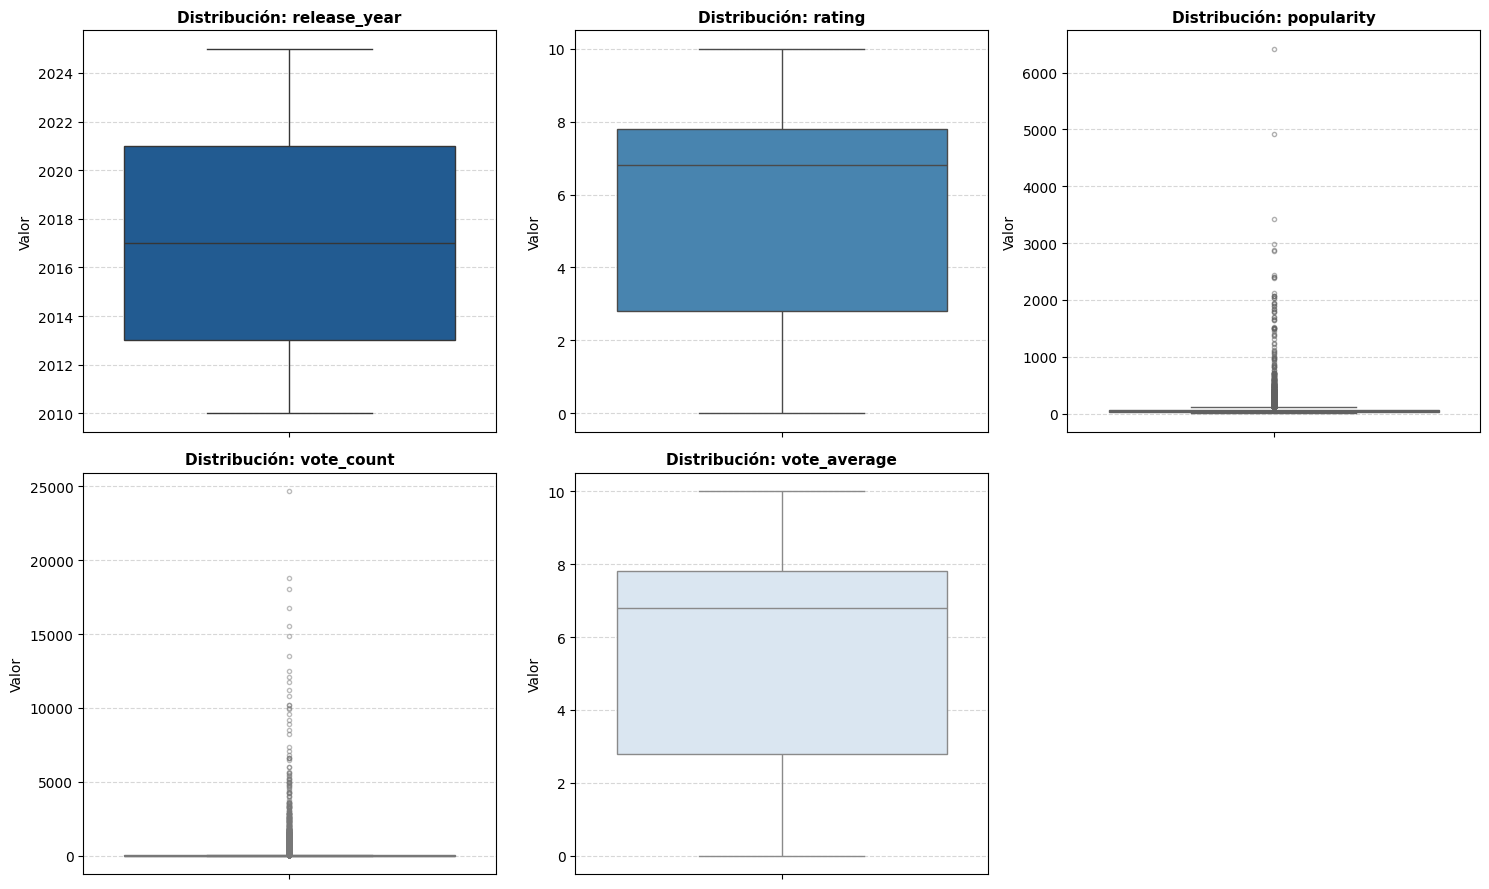

In [ ]:
"""
Visualización y Análisis Exploratorio de Variables Numéricas: Catálogo de Series (df_shows)
=========================================================================================

Propósito Metodológico (Visual Analytics - EDA):
------------------------------------------------
Genera una cuadrícula de diagramas de caja (boxplots) individuales sobre los datos crudos
para examinar la dispersión, la simetría de los cuartiles (IQR) y la presencia de valores
atípicos (outliers) en las variables cuantitativas del catálogo de series de StreamView Analytics.

Diferencias Estructurales con el Catálogo de Películas:
-------------------------------------------------------
- Exclusión Financiera Obligatoria: A diferencia de 'df_movies', el archivo de series no
  incluye las variables 'budget' ni 'revenue' (regla de negocio estricta del caso).
- Escalas Independientes: Cada variable se grafica en su propio eje para evitar que métricas
  con órdenes de magnitud dispares (como 'popularity' frente a 'vote_average' en escala [0, 10])
  se aplasten visualmente[cite: 1, 5].
- Manejo de Tipos: Se descartan columnas no numéricas o 100% vacías, y se limpian valores nulos
  con dropna() al graficar para prevenir fallas de renderizado en Matplotlib.
"""

# 1. Obtención de datos numéricos crudos y despliegue de estadísticas descriptivas
df_shows_numerico = df_shows.drop(columns="show_id", errors="ignore").select_dtypes(include=['int', 'float'])
display(df_shows_numerico.describe())

# 2. Identificar columnas numéricas que contengan datos válidos
cols_shows = [c for c in df_shows_numerico.columns if df_shows_numerico[c].dropna().shape[0] > 0]
n_cols = len(cols_shows)

# 3. Configuración de la cuadrícula de subplots
grid_cols = 3
grid_rows = math.ceil(n_cols / grid_cols)

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(15, 4.5 * grid_rows))
axes = axes.flatten() if n_cols > 1 else [axes]
palette = sns.color_palette("Blues_r", n_cols)

# 4. Trazado de Boxplots individuales
for i, col in enumerate(cols_shows):
    serie_limpia = df_shows_numerico[col].dropna()
    sns.boxplot(
        y=serie_limpia,
        ax=axes[i],
        color=palette[i],
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.5}
    )
    axes[i].set_title(f"Distribución: {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Valor")
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)

# 5. Ocultar paneles sobrantes en caso de cuadrícula incompleta
for j in range(len(cols_shows), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

A continuación se detalla la interpretación estadística y el hallazgo de negocio para cada uno de los 5 diagramas de caja obtenidos,

---

#### 1. Variable: `release_year`

* **Tipo de dato:** Cuantitativo Discreto / Secuencia Temporal.


* **Comportamiento visual:** La mediana se ubica en el año **2017**, con el 50% central de las producciones seriadas (rango intercuartílico IQR) distribuido entre **2013 (Q1)** y **2021 (Q3)**. Los bigotes cubren el rango desde 2010 hasta 2025 sin presencia de *outliers* fuera de este intervalo en el dataset.
* **Descubrimiento (Hallazgo clave):** El catálogo de series está enfocado en la era dorada del streaming moderno (producciones posteriores a 2010), evidenciando una oferta televisiva contemporánea y prácticamente nula presencia de series clásicas del siglo XX.


* **Implicancia de negocio:** El contenido seriado moderno tiene un ciclo de obsolescencia acelerado; la Gerencia de Contenidos debe planificar incorporaciones constantes para evitar que el catálogo envejezca rápidamente a ojos de los suscriptores.



---

#### 2. Variable: `rating`

* **Tipo de dato:** Cuantitativo Continuo (escala de evaluación 0 a 10).


* **Comportamiento visual:** Presenta una marcada asimetría hacia los valores bajos: la mediana se ubica alta, en torno a **6.8**, y el cuartil superior (Q3) llega a **7.8**. Sin embargo, el cuartil inferior (Q1) cae abruptamente hasta **~2.8**, con el bigote inferior extendiéndose hasta **0.0** y el superior hasta **10.0**.
* **Descubrimiento (Hallazgo clave):** Existe una fuerte polarización: el 50% superior del catálogo cuenta con evaluaciones notables (entre 6.8 y 10), pero al menos un 25% del inventario posee calificaciones deficientes o registros en cero (series sin recepción o con recepción crítica muy negativa).


* **Implicancia de negocio:** Representa una alerta de calidad. El catálogo arrastra series con valoración inferior a 3.0 que aumentan el costo de almacenamiento y licenciamiento sin aportar valor cualitativo a la plataforma (componente del "catálogo zombie").



---

#### 3. Variable: `popularity`

* **Tipo de dato:** Cuantitativo Continuo (Índice relativo de tracción).


* **Comportamiento visual:** Asimetría positiva extrema (*right-skewed*). La caja intercuartílica y la mediana están totalmente aplastadas en la base (valores inferiores a 100). Se observa una densa columna de valores atípicos que se eleva superando los 1.000 y 2.000 puntos, con fenómenos virales aislados que marcan picos atípicos en **3.400, 4.900 y sobre los 6.400 puntos**.


* **Descubrimiento (Hallazgo clave):** Menos del 1% de las series del catálogo actúa como motor masivo de tracción y conversación en la plataforma, mientras que más del 90% opera en niveles basales de popularidad.


* **Implicancia de negocio:** Valida la regla estricta del caso de **no confundir popularidad con reproducciones absolutas**. Para la Gerencia de Marketing, confirma que la atención está hiperconcentrada en pocos lanzamientos globales, lo que exige diseñar campañas específicas para redistribuir el tráfico hacia series de calidad que carecen de visibilidad.



---

#### 4. Variable: `vote_count`

* **Tipo de dato:** Cuantitativo Discreto (Conteo acumulado).


* **Comportamiento visual:** Concentración masiva en el origen (la mediana y el IQR están pegados a cero, representando producciones con menos de 50 votos). Los valores atípicos ascienden de forma continua hasta los 5.000 votos, alcanzando registros extremos en torno a los **17.000, 19.000 y cerca de 25.000 votos**.
* **Descubrimiento (Hallazgo clave):** La gran mayoría de las series en la plataforma cuenta con una base de evaluadores mínima, lo que genera alta volatilidad estadística en las calificaciones promedio de producciones poco conocidas.


* **Implicancia de negocio:** Es metodológicamente mandatorio aplicar un filtro de representatividad (ej. `vote_count >= 30` o `50`) antes de seleccionar títulos para rankings corporativos o campañas comerciales, evitando recomendar series con calificaciones perfectas sustentadas por solo uno o dos votos.



---

#### 5. Variable: `vote_average`

* **Tipo de dato:** Cuantitativo Continuo (restringido a escala [0.0, 10.0]).


* **Comportamiento visual:** Distribución idéntica a la variable `rating` (mediana en **~6.8**, Q1 en **~2.8**, Q3 en **~7.8**, con bigotes entre 0.0 y 10.0).
* **Descubrimiento (Hallazgo clave):** Confirma duplicidad o redundancia directa entre `rating` y `vote_average` en el registro de series de televisión, midiendo el mismo atributo de satisfacción del usuario.


* **Implicancia de negocio:** Para la construcción del dashboard corporativo, se debe eliminar la redundancia y estandarizar el uso exclusivo de `vote_average` como métrica cardinal de calidad. Aquellas series situadas en el percentil 75 hacia arriba (


$$vote\_average \ge 7.8$$


) con baja popularidad definen el segmento objetivo de **"Gemas Ocultas"** para fidelizar suscriptores.



---

**Nota de Gobernanza de Datos y Cumplimiento de Reglas:**

La generación de exactamente **5 gráficos** en series (a diferencia de los 7 observados en películas) demuestra el cumplimiento de la regla de negocio del caso: las variables financieras `budget` y `revenue` no existen ni aplican al formato serializado, evitando imputaciones erróneas de rentabilidad sobre este conjunto de datos.

In [ ]:
# ==============================================================================
# 0. INSTALAR MOTOR DE EXCEL DE ALTO RENDIMIENTO (Obligatorio en Colab)
# ==============================================================================
!pip install xlsxwriter

import pandas as pd
import numpy as np

# 1. Definición de los archivos de origen
archivo_valoraciones = "L2_A16_valoraciones_usuarios (1).csv"

# 2. Carga de los datos
print("\nCargando datasets...")
try:
    df_valoraciones = pd.read_csv(archivo_valoraciones)
    print(f"-> Valoraciones cargadas: {df_valoraciones.shape[0]} filas, {df_valoraciones.shape[1]} columnas.")
except FileNotFoundError:
    print(f"Error: No se encontró el archivo {archivo_valoraciones}")

# Carga directa desde GitHub para películas y series
url_movies = "https://raw.githubusercontent.com/YorkiOprogramador/VisualizacionDeDatos_Encargo1/main/data/netflix_movies_detailed_up_to_2025.csv"
url_shows = "https://raw.githubusercontent.com/YorkiOprogramador/VisualizacionDeDatos_Encargo1/main/data/netflix_tv_shows_detailed_up_to_2025.csv"
df_movies = pd.read_csv(url_movies)
df_shows = pd.read_csv(url_shows)
print(f"-> Películas cargadas: {df_movies.shape[0]} filas, {df_movies.shape[1]} columnas.")
print(f"-> Series cargadas:    {df_shows.shape[0]} filas, {df_shows.shape[1]} columnas.")

# ==============================================================================
# 3. FUNCIÓN DE LIMPIEZA Y TIPIFICACIÓN ESTRICTA (PARA EXCEL)
# ==============================================================================
def normalizar_tipos_excel(df, es_pelicula=True):
    df_clean = df.copy()

    # A. Identificador único: texto
    if 'show_id' in df_clean.columns:
        df_clean['show_id'] = df_clean['show_id'].astype(str)

    # B. Fechas: conversión a DateTime real y desglose en jerarquías temporales
    if 'date_added' in df_clean.columns:
        df_clean['date_added'] = pd.to_datetime(df_clean['date_added'], errors='coerce')

        # Desglose para facilitar filtros en Power BI (Int64 preserva nulos sin romper el tipo numérico)
        df_clean['year_added'] = df_clean['date_added'].dt.year.astype('Int64')
        df_clean['quarter_added'] = df_clean['date_added'].dt.quarter.astype('Int64')
        df_clean['month_added'] = df_clean['date_added'].dt.month.astype('Int64')
        df_clean['day_added'] = df_clean['date_added'].dt.day.astype('Int64')

    # C. Años y conteos: enteros
    if 'release_year' in df_clean.columns:
        df_clean['release_year'] = pd.to_numeric(df_clean['release_year'], errors='coerce').astype('Int64')

    if 'vote_count' in df_clean.columns:
        df_clean['vote_count'] = pd.to_numeric(df_clean['vote_count'], errors='coerce').astype('Int64')

    # D. Métricas continuas / decimales (CRÍTICO: float nativo)
    if 'vote_average' in df_clean.columns:
        df_clean['vote_average'] = pd.to_numeric(df_clean['vote_average'], errors='coerce').astype(float)

    if 'popularity' in df_clean.columns:
        df_clean['popularity'] = pd.to_numeric(df_clean['popularity'], errors='coerce').astype(float)

    # E. Variables financieras
    if es_pelicula:
        if 'budget' in df_clean.columns:
            df_clean['budget'] = pd.to_numeric(df_clean['budget'], errors='coerce').astype(float)
        if 'revenue' in df_clean.columns:
            df_clean['revenue'] = pd.to_numeric(df_clean['revenue'], errors='coerce').astype(float)

    # F. Textos
    columnas_texto = ['type', 'title', 'director', 'cast', 'country',
                      'rating', 'duration', 'genres', 'language', 'description']
    for col in columnas_texto:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].fillna('').astype(str)

    return df_clean

print("\nTipificando columnas y convirtiendo formatos numéricos y fechas...")
df_movies_clean = normalizar_tipos_excel(df_movies, es_pelicula=True)
df_shows_clean = normalizar_tipos_excel(df_shows, es_pelicula=False)

# ==============================================================================
# 4. ELIMINAR DUPLICADOS EN SERIES
# ==============================================================================
total_antes = df_shows_clean.shape[0]
df_shows_clean.drop_duplicates(subset=['show_id'], keep='first', inplace=True)
total_despues = df_shows_clean.shape[0]
print(f"\nSe eliminaron {total_antes - total_despues} filas duplicadas en el catálogo de series.")

# ==============================================================================
# 5. CREAR TABLA CONSOLIDADA E IMPORTAR A EXCEL (.xlsx)
# ==============================================================================
df_consolidado = pd.concat([df_movies_clean, df_shows_clean], ignore_index=True)
archivo_master = "StreamView_Catalogo_Master_Limpio.xlsx"

print("\nGenerando archivo Excel consolidado...")
# Ahora funcionará porque instalamos xlsxwriter al inicio
with pd.ExcelWriter(archivo_master, engine='xlsxwriter') as writer:
    df_consolidado.to_excel(writer, sheet_name='Catalogo_Consolidado', index=False)
    df_movies_clean.to_excel(writer, sheet_name='Peliculas', index=False)
    df_shows_clean.to_excel(writer, sheet_name='Series', index=False)

print("¡Archivo Excel creado con éxito!")

# ==============================================================================
# 6. DESCARGAR AUTOMÁTICAMENTE
# ==============================================================================
try:
    from google.colab import files
    print("\nIniciando descarga a tu computador...")
    files.download(archivo_master)
except ImportError:
    print(f"\nEl archivo se guardó localmente en el directorio actual: {archivo_master}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 5.7 MB/s eta 0:00:00

Cargando datasets...
Error: No se encontró el archivo L2_A16_valoraciones_usuarios (1).csv
-> Películas cargadas: 16000 filas, 18 columnas.
-> Series cargadas:    16000 filas, 16 columnas.

Tipificando columnas y convirtiendo formatos numéricos y fechas...

Se eliminaron 9 filas duplicadas en el catálogo de series.

Generando archivo Excel consolidado...
¡Archivo Excel creado con éxito!

Iniciando descarga a tu computador...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Dimensiones del dataset: (31991, 22)

Tipos de contenido:
type
Movie      16000
TV Show    15991
Name: count, dtype: int64

VALORES NULOS - Movies


,Cantidad de nulos,Porcentaje
duration,16000,100.00
country,466,2.91
cast,204,1.27
director,132,0.82
description,132,0.82
genres,107,0.67


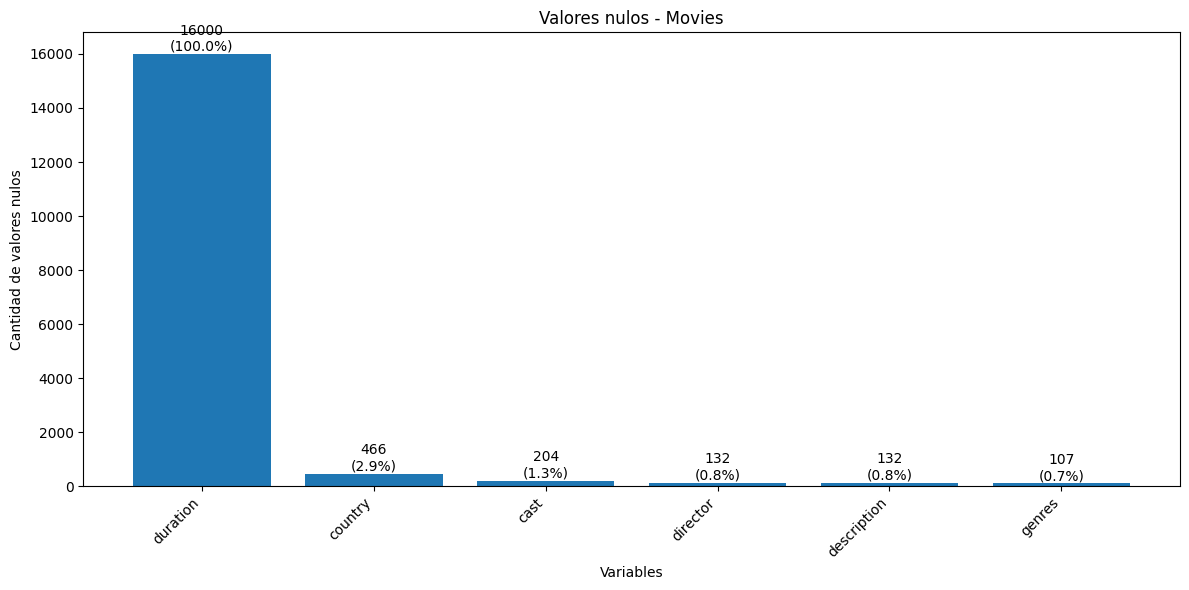


VALORES NULOS - TV Shows


,Cantidad de nulos,Porcentaje
revenue,15991,100.00
budget,15991,100.00
director,10960,68.54
description,3203,20.03
country,1795,11.23
cast,1156,7.23
genres,972,6.08


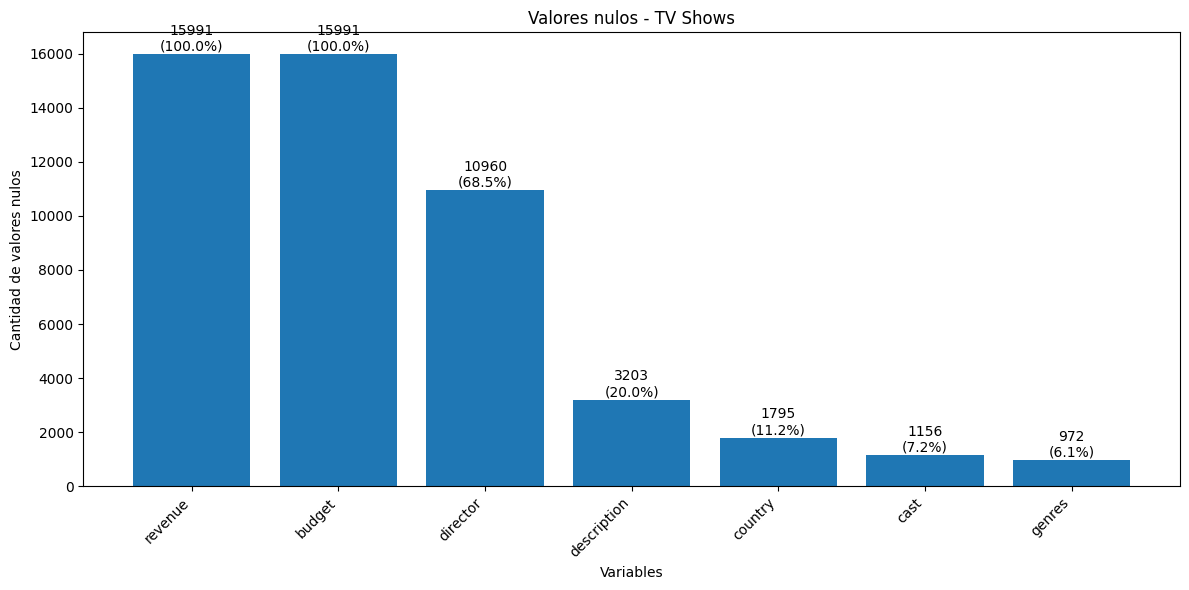

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CARGAR DATASET UNIFICADO
# ============================================================

df = pd.read_excel("StreamView_Catalogo_Master_Limpio.xlsx")

print("Dimensiones del dataset:", df.shape)
print("\nTipos de contenido:")
print(df["type"].value_counts())


# ============================================================
# 2. SEPARAR MOVIES Y TV SHOWS
# ============================================================

movies = df[df["type"] == "Movie"].copy()
tv_shows = df[df["type"] == "TV Show"].copy()


# ============================================================
# 3. FUNCIÓN PARA CALCULAR Y GRAFICAR NULOS
# ============================================================

def graficar_nulos(data, nombre_dataset):

    # Cantidad de nulos por columna
    nulos = data.isnull().sum()

    # Mantener solo columnas con nulos
    nulos = nulos[nulos > 0].sort_values(ascending=False)

    # Calcular porcentaje
    porcentajes = (nulos / len(data)) * 100

    # Mostrar tabla
    tabla = pd.DataFrame({
        "Cantidad de nulos": nulos,
        "Porcentaje": porcentajes.round(2)
    })

    print(f"\n{'='*50}")
    print(f"VALORES NULOS - {nombre_dataset}")
    print(f"{'='*50}")
    display(tabla)

    # Gráfico
    plt.figure(figsize=(12, 6))

    bars = plt.bar(
        nulos.index,
        nulos.values
    )

    plt.title(f"Valores nulos - {nombre_dataset}")
    plt.xlabel("Variables")
    plt.ylabel("Cantidad de valores nulos")
    plt.xticks(rotation=45, ha="right")

    # Etiquetas con cantidad y porcentaje
    for bar, porcentaje in zip(bars, porcentajes):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(bar.get_height())}\n({porcentaje:.1f}%)",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()


# ============================================================
# 4. GRÁFICO MOVIES
# ============================================================

graficar_nulos(
    movies,
    "Movies"
)


# ============================================================
# 5. GRÁFICO TV SHOWS
# ============================================================

graficar_nulos(
    tv_shows,
    "TV Shows"
)

In [ ]:
StreamView_Catalogo_Master_Limpio.xlsx